# Pipeline de Machine Learning complet — bonnes pratiques

**Règle d'or : on sépare train / val / test AVANT tout prétraitement appris sur les données.**

| Étape | Avant le split ? | Pourquoi |
|---|---|---|
| Nettoyage « sans apprentissage » (doublons, types, corriger des valeurs aberrantes évidentes, feature engineering ligne par ligne) | ✅ Oui | Ne dépend d'aucune statistique globale |
| Imputation (moyenne, médiane, mode) | ❌ Non → après | La moyenne calculée sur tout le dataset contient de l'info du test |
| Normalisation / standardisation | ❌ Non → après | Le `mean`/`std` du scaler doit venir du train uniquement |
| Encodage (One-Hot, Ordinal, Target encoding) | ❌ Non → après | Les catégories / statistiques (surtout target encoding) doivent venir du train |
| Sélection de features, PCA, rééquilibrage (SMOTE) | ❌ Non → après | Même raison ; SMOTE uniquement sur le train |

Le principe : **`fit` sur le train, `transform` sur train, val et test.**
Le plus sûr est de tout mettre dans un `Pipeline` scikit-learn : il garantit qu'aucune fuite n'est possible, même en validation croisée.

Plan du notebook :
1. Imports et configuration
2. Chargement des données
3. Nettoyage sans apprentissage
4. Split train / val / test (stratifié)
5. EDA sur le **train uniquement**
6. Préprocesseur (`ColumnTransformer`)
7. Baseline
8. Comparaison de modèles en validation croisée (train)
9. Optimisation des hyperparamètres (train) + contrôle sur val
10. Évaluation finale **une seule fois** sur le test
11. Démonstration de la fuite de données
12. Sauvegarde et inférence


## 1. Imports et configuration

In [1]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

## 2. Chargement des données

Pour que le notebook tourne sans téléchargement, on génère un dataset synthétique de **churn client** réaliste : variables numériques, catégorielles, une variable ordinale, des valeurs manquantes et une classe déséquilibrée.
👉 Remplace simplement `make_churn_dataset()` par `pd.read_csv("ton_fichier.csv")`.

In [2]:
def make_churn_dataset(n_samples=5000, seed=42):
    """
    Generate a synthetic customer churn dataset with mixed feature types.

    Parameters
    ----------
    n_samples : int, default=5000
        Number of rows to generate.
    seed : int, default=42
        Random seed for reproducibility.

    Returns
    -------
    pandas.DataFrame
        Dataset with numerical, categorical and ordinal features, missing
        values, duplicated rows and a binary target column ``churn``.
    """
    rng = np.random.default_rng(seed)
    age = rng.normal(42, 12, n_samples).clip(18, 80).round()
    tenure = rng.exponential(30, n_samples).clip(0, 120).round()
    monthly = rng.normal(65, 25, n_samples).clip(10, 200).round(2)
    support_calls = rng.poisson(1.5, n_samples)
    contract = rng.choice(["mensuel", "annuel", "biannuel"], n_samples, p=[0.55, 0.3, 0.15])
    payment = rng.choice(["carte", "prelevement", "virement", "cheque"], n_samples)
    region = rng.choice(["IDF", "Nord", "Sud", "Est", "Ouest"], n_samples)
    satisfaction = rng.choice(["faible", "moyenne", "elevee"], n_samples, p=[0.25, 0.45, 0.30])

    logit = (
        -1.2
        + 0.9 * (contract == "mensuel")
        - 0.03 * tenure
        + 0.015 * (monthly - 65)
        + 0.35 * support_calls
        + 0.8 * (satisfaction == "faible")
        - 0.6 * (satisfaction == "elevee")
        + 0.3 * (payment == "cheque")
    )
    churn = rng.binomial(1, 1 / (1 + np.exp(-logit)))

    df = pd.DataFrame(
        {
            "customer_id": np.arange(n_samples),
            "age": age,
            "tenure_months": tenure,
            "monthly_charges": monthly,
            "support_calls": support_calls,
            "contract": contract,
            "payment_method": payment,
            "region": region,
            "satisfaction": satisfaction,
            "churn": churn,
        }
    )
    for col, rate in [("age", 0.05), ("monthly_charges", 0.03), ("payment_method", 0.04), ("satisfaction", 0.06)]:
        df.loc[rng.random(n_samples) < rate, col] = np.nan
    duplicates = df.sample(50, random_state=seed)
    return pd.concat([df, duplicates], ignore_index=True)


df_raw = make_churn_dataset()
print(df_raw.shape)
df_raw.head()

(5050, 10)


,customer_id,age,tenure_months,monthly_charges,support_calls,contract,payment_method,region,satisfaction,churn
0,0,46.0,20.0,67.34,0,mensuel,prelevement,Est,elevee,0
1,1,NaN,28.0,96.32,2,annuel,prelevement,Sud,moyenne,1
2,2,51.0,13.0,103.49,0,biannuel,carte,Nord,moyenne,0
3,3,NaN,47.0,77.61,1,mensuel,cheque,Ouest,elevee,1
4,4,19.0,3.0,118.53,1,mensuel,prelevement,IDF,elevee,0


## 3. Nettoyage « sans apprentissage » (OK avant le split)

Ici on ne fait **que** des opérations qui traitent chaque ligne indépendamment, sans calculer de statistique sur l'ensemble des données : suppression des doublons, colonnes inutiles (identifiants), création de features ligne par ligne.

In [3]:
def clean_without_fitting(df):
    """
    Apply row-wise cleaning steps that do not learn any statistic from the data.

    Parameters
    ----------
    df : pandas.DataFrame
        Raw dataset.

    Returns
    -------
    pandas.DataFrame
        Dataset without duplicates or identifier column, with a new
        row-wise engineered feature ``charges_per_tenure``.
    """
    out = df.drop_duplicates().drop(columns=["customer_id"]).reset_index(drop=True)
    out["charges_per_tenure"] = out["monthly_charges"] / (out["tenure_months"] + 1)
    return out


df = clean_without_fitting(df_raw)
print(f"Lignes : {len(df_raw)} -> {len(df)}")
print(df["churn"].value_counts(normalize=True).round(3))

Lignes : 5050 -> 5000
churn
0    0.685
1    0.315
Name: proportion, dtype: float64


## 4. Split train / validation / test

- **Stratifié** sur la cible pour garder le même taux de churn partout.
- 60 % train / 20 % val / 20 % test.
- Le **test est mis de côté** et ne sera utilisé qu'une seule fois, à la toute fin.

> Si tes données ont une dimension temporelle, fais un split chronologique (passé → train, futur → test) au lieu d'un split aléatoire. Si plusieurs lignes appartiennent à la même entité (même client, même patient), utilise `GroupShuffleSplit` pour éviter qu'une entité soit à la fois dans le train et le test.

In [4]:
def split_train_val_test(df, target, val_size=0.2, test_size=0.2, seed=42):
    """
    Split a dataset into stratified train, validation and test sets.

    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned dataset including the target column.
    target : str
        Name of the target column.
    val_size : float, default=0.2
        Fraction of the full dataset used for validation.
    test_size : float, default=0.2
        Fraction of the full dataset used for testing.
    seed : int, default=42
        Random seed.

    Returns
    -------
    tuple of pandas.DataFrame and pandas.Series
        ``X_train, X_val, X_test, y_train, y_val, y_test``.
    """
    X = df.drop(columns=[target])
    y = df[target]
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed
    )
    relative_val = val_size / (1 - test_size)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=relative_val, stratify=y_temp, random_state=seed
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


TARGET = "churn"
X_train, X_val, X_test, y_train, y_val, y_test = split_train_val_test(df, TARGET, seed=SEED)
for name, X_, y_ in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s} : {X_.shape[0]:5d} lignes | taux de churn = {y_.mean():.3f}")

train :  3000 lignes | taux de churn = 0.316
val   :  1000 lignes | taux de churn = 0.315
test  :  1000 lignes | taux de churn = 0.315


## 5. EDA sur le train uniquement

On explore **seulement le train**. Regarder le test pour prendre des décisions (choix de features, seuils…) est déjà une forme de fuite.

In [5]:
def describe_features(X, y):
    """
    Print a compact overview of missing values, types and target relation.

    Parameters
    ----------
    X : pandas.DataFrame
        Feature matrix (training set only).
    y : pandas.Series
        Target vector aligned with ``X``.

    Returns
    -------
    pandas.DataFrame
        Summary table with dtype, missing rate and number of unique values.
    """
    summary = pd.DataFrame(
        {
            "dtype": X.dtypes.astype(str),
            "missing_%": (X.isna().mean() * 100).round(2),
            "n_unique": X.nunique(),
        }
    )
    return summary


display(describe_features(X_train, y_train))
display(X_train.describe().T.round(2))

,dtype,missing_%,n_unique
age,float64,5.40,62
tenure_months,float64,0.00,119
monthly_charges,float64,3.60,2415
support_calls,int64,0.00,8
contract,str,0.00,3
payment_method,str,3.70,4
region,str,0.00,5
satisfaction,str,6.03,3
charges_per_tenure,float64,3.60,2871


,count,mean,std,min,25%,50%,75%,max
age,2838.0,41.97,11.82,18.00,34.00,42.00,50.00,79.00
tenure_months,3000.0,29.15,27.66,0.00,9.00,21.00,41.00,120.00
monthly_charges,2892.0,64.80,24.61,10.00,48.09,64.12,80.86,168.78
support_calls,3000.0,1.51,1.22,0.00,1.00,1.00,2.00,7.00
charges_per_tenure,2892.0,6.83,12.24,0.09,1.40,2.86,6.64,141.13


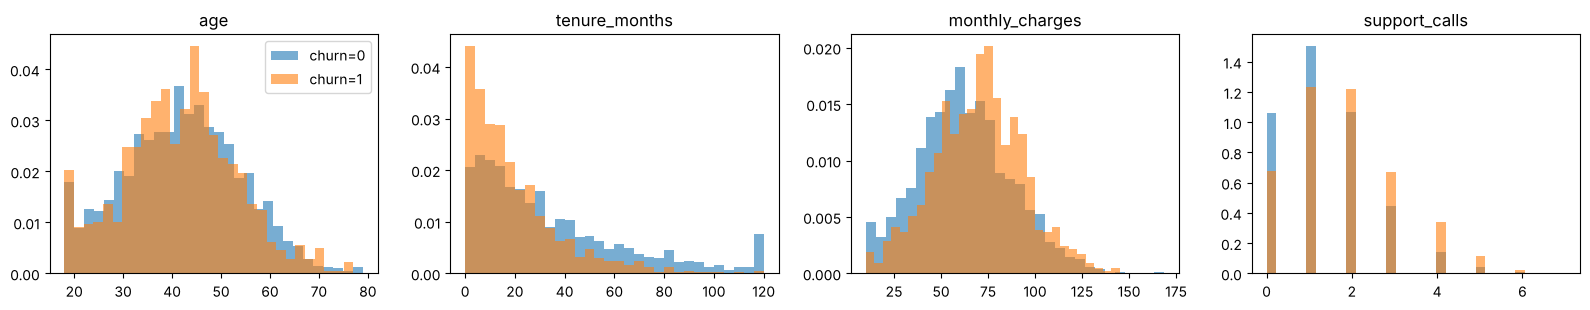

churn,0,1
contract,,
annuel,0.755,0.245
biannuel,0.750,0.250
mensuel,0.628,0.372


In [6]:
def plot_numeric_distributions(X, y, columns):
    """
    Plot the distribution of numeric features split by target class.

    Parameters
    ----------
    X : pandas.DataFrame
        Feature matrix (training set only).
    y : pandas.Series
        Binary target vector aligned with ``X``.
    columns : list of str
        Numeric columns to plot.

    Returns
    -------
    None
    """
    fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 3.2))
    for ax, col in zip(axes, columns):
        for label in sorted(y.unique()):
            ax.hist(X.loc[y == label, col].dropna(), bins=30, alpha=0.6, density=True, label=f"churn={label}")
        ax.set_title(col)
    axes[0].legend()
    plt.tight_layout()
    plt.show()


plot_numeric_distributions(X_train, y_train, ["age", "tenure_months", "monthly_charges", "support_calls"])
pd.crosstab(X_train["contract"], y_train, normalize="index").round(3)

## 6. Préprocesseur : `ColumnTransformer`

Chaque type de colonne a son traitement :

- **Numériques** → imputation par la médiane + `StandardScaler`
- **Nominales** → imputation par la modalité la plus fréquente + `OneHotEncoder(handle_unknown="ignore")` (une catégorie jamais vue en train ne fait pas planter l'inférence)
- **Ordinale** (`satisfaction`) → `OrdinalEncoder` avec l'ordre explicite

Tout ça est encapsulé : quand on appellera `pipeline.fit(X_train, y_train)`, les médianes, moyennes, écarts-types et catégories seront appris **uniquement sur le train**.

In [7]:
NUMERIC_COLS = ["age", "tenure_months", "monthly_charges", "support_calls", "charges_per_tenure"]
NOMINAL_COLS = ["contract", "payment_method", "region"]
ORDINAL_COLS = ["satisfaction"]
ORDINAL_ORDER = [["faible", "moyenne", "elevee"]]


def build_preprocessor(scale_numeric=True):
    """
    Build the column-wise preprocessing transformer.

    Parameters
    ----------
    scale_numeric : bool, default=True
        Whether to standardize numeric features. Tree-based models do not
        need scaling, linear models and neural networks do.

    Returns
    -------
    sklearn.compose.ColumnTransformer
        Unfitted transformer handling numeric, nominal and ordinal columns.
    """
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)
    nominal_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    ordinal_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(categories=ORDINAL_ORDER)),
        ]
    )
    return ColumnTransformer(
        [
            ("num", numeric_pipe, NUMERIC_COLS),
            ("nom", nominal_pipe, NOMINAL_COLS),
            ("ord", ordinal_pipe, ORDINAL_COLS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def build_pipeline(model, scale_numeric=True):
    """
    Chain the preprocessor and an estimator into a single pipeline.

    Parameters
    ----------
    model : sklearn estimator
        Classifier to train after preprocessing.
    scale_numeric : bool, default=True
        Passed to :func:`build_preprocessor`.

    Returns
    -------
    sklearn.pipeline.Pipeline
        Unfitted end-to-end pipeline.
    """
    return Pipeline([("prep", build_preprocessor(scale_numeric)), ("model", model)])

Vérification : on *fit* le préprocesseur sur le train, puis on se contente de *transformer* val et test.
Le train transformé a une moyenne ≈ 0 et un écart-type ≈ 1 ; val et test seulement *approximativement* — c'est normal et c'est exactement ce qu'on veut (ils sont traités comme des données « jamais vues »).

In [8]:
prep = build_preprocessor()
Xt_train = prep.fit_transform(X_train)
Xt_val = prep.transform(X_val)
Xt_test = prep.transform(X_test)

feature_names = prep.get_feature_names_out()
print(f"{len(feature_names)} features après encodage :", list(feature_names))

num_idx = list(range(len(NUMERIC_COLS)))
check = pd.DataFrame(
    {
        "train_mean": Xt_train[:, num_idx].mean(0),
        "val_mean": Xt_val[:, num_idx].mean(0),
        "test_mean": Xt_test[:, num_idx].mean(0),
        "train_std": Xt_train[:, num_idx].std(0),
        "test_std": Xt_test[:, num_idx].std(0),
    },
    index=NUMERIC_COLS,
).round(3)
check

18 features après encodage : ['age', 'tenure_months', 'monthly_charges', 'support_calls', 'charges_per_tenure', 'contract_annuel', 'contract_biannuel', 'contract_mensuel', 'payment_method_carte', 'payment_method_cheque', 'payment_method_prelevement', 'payment_method_virement', 'region_Est', 'region_IDF', 'region_Nord', 'region_Ouest', 'region_Sud', 'satisfaction']


,train_mean,val_mean,test_mean,train_std,test_std
age,0.0,0.029,-0.063,1.0,0.977
tenure_months,-0.0,0.005,0.017,1.0,1.030
monthly_charges,-0.0,0.023,-0.016,1.0,1.016
support_calls,-0.0,0.022,0.034,1.0,1.042
charges_per_tenure,-0.0,-0.009,0.010,1.0,0.951


## 7. Baseline

Toujours commencer par un modèle naïf : il donne le score plancher à battre. Avec une classe déséquilibrée, l'**accuracy** est trompeuse → on suit plutôt **ROC-AUC**, **PR-AUC** (average precision) et **F1**.

In [9]:
def evaluate(model, X, y, name):
    """
    Compute classification metrics for a fitted pipeline.

    Parameters
    ----------
    model : sklearn estimator
        Fitted classifier or pipeline exposing ``predict_proba``.
    X : pandas.DataFrame
        Features to score.
    y : pandas.Series
        True labels.
    name : str
        Label for the row in the returned table.

    Returns
    -------
    pandas.DataFrame
        One-row table with ROC-AUC, PR-AUC and F1 score.
    """
    proba = model.predict_proba(X)[:, 1]
    pred = model.predict(X)
    return pd.DataFrame(
        {
            "roc_auc": [roc_auc_score(y, proba)],
            "pr_auc": [average_precision_score(y, proba)],
            "f1": [f1_score(y, pred, zero_division=0)],
        },
        index=[name],
    ).round(4)


baseline = build_pipeline(DummyClassifier(strategy="prior")).fit(X_train, y_train)
evaluate(baseline, X_val, y_val, "baseline (val)")

,roc_auc,pr_auc,f1
baseline (val),0.5,0.315,0.0


## 8. Comparaison de modèles en validation croisée (sur le train)

Le `Pipeline` est passé **entier** à `cross_validate` : à chaque fold, le scaler et l'encodeur sont ré-appris sur les 4/5 d'entraînement du fold et appliqués au 1/5 restant. Aucune fuite, même à l'intérieur de la CV.

In [10]:
def compare_models(candidates, X, y, cv):
    """
    Compare several pipelines with stratified cross-validation.

    Parameters
    ----------
    candidates : dict
        Mapping ``name -> unfitted pipeline``.
    X : pandas.DataFrame
        Training features.
    y : pandas.Series
        Training labels.
    cv : cross-validation splitter
        For instance a ``StratifiedKFold`` instance.

    Returns
    -------
    pandas.DataFrame
        Mean and standard deviation of each metric per model, sorted by ROC-AUC.
    """
    rows = []
    for name, pipe in candidates.items():
        scores = cross_validate(pipe, X, y, cv=cv, scoring=["roc_auc", "average_precision", "f1"], n_jobs=-1)
        rows.append(
            {
                "model": name,
                "roc_auc": scores["test_roc_auc"].mean(),
                "roc_auc_std": scores["test_roc_auc"].std(),
                "pr_auc": scores["test_average_precision"].mean(),
                "f1": scores["test_f1"].mean(),
            }
        )
    return pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False).round(4)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    "logreg": build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "random_forest": build_pipeline(
        RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
        scale_numeric=False,
    ),
    "hist_gb": build_pipeline(
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
        scale_numeric=False,
    ),
}
cv_results = compare_models(candidates, X_train, y_train, cv)
cv_results

,roc_auc,roc_auc_std,pr_auc,f1
model,,,,
logreg,0.7493,0.0155,0.5950,0.5685
random_forest,0.7092,0.0182,0.5301,0.5048
hist_gb,0.7071,0.0103,0.5377,0.5217


## 9. Optimisation des hyperparamètres + contrôle sur la validation

- La recherche (`RandomizedSearchCV`) se fait **en CV sur le train**.
- Le set de **validation** sert ensuite à vérifier que le modèle choisi généralise, et à régler le **seuil de décision**.
- On note les hyperparamètres via `model__<param>` grâce au `Pipeline`.

In [11]:
def tune_logreg(X, y, cv, n_iter=25, seed=42):
    """
    Tune a logistic regression pipeline with randomized search.

    Parameters
    ----------
    X : pandas.DataFrame
        Training features.
    y : pandas.Series
        Training labels.
    cv : cross-validation splitter
        Splitter used inside the search.
    n_iter : int, default=25
        Number of sampled parameter settings.
    seed : int, default=42
        Random seed.

    Returns
    -------
    sklearn.model_selection.RandomizedSearchCV
        Fitted search object; ``best_estimator_`` is refit on all of ``X``.
    """
    param_dist = {
        "model__C": np.logspace(-3, 2, 30),
        "model__penalty": ["l1", "l2"],
        "model__solver": ["liblinear"],
    }
    search = RandomizedSearchCV(
        build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")),
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring="roc_auc",
        cv=cv,
        random_state=seed,
        n_jobs=-1,
    )
    return search.fit(X, y)


def tune_hist_gb(X, y, cv, n_iter=25, seed=42):
    """
    Tune a histogram gradient boosting pipeline with randomized search.

    Parameters
    ----------
    X : pandas.DataFrame
        Training features.
    y : pandas.Series
        Training labels.
    cv : cross-validation splitter
        Splitter used inside the search.
    n_iter : int, default=25
        Number of sampled parameter settings.
    seed : int, default=42
        Random seed.

    Returns
    -------
    sklearn.model_selection.RandomizedSearchCV
        Fitted search object; ``best_estimator_`` is refit on all of ``X``.
    """
    param_dist = {
        "model__learning_rate": np.logspace(-2.5, -0.5, 20),
        "model__max_depth": [None, 3, 4, 6, 8],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [10, 20, 50, 100],
        "model__l2_regularization": np.logspace(-3, 1, 10),
    }
    search = RandomizedSearchCV(
        build_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=seed), scale_numeric=False),
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring="roc_auc",
        cv=cv,
        random_state=seed,
        n_jobs=-1,
    )
    return search.fit(X, y)


searches = {"logreg": tune_logreg(X_train, y_train, cv, seed=SEED), "hist_gb": tune_hist_gb(X_train, y_train, cv, seed=SEED)}
for name, s in searches.items():
    print(f"{name:8s} CV ROC-AUC = {s.best_score_:.4f} | {s.best_params_}")

val_table = pd.concat([evaluate(s.best_estimator_, X_val, y_val, f"{n} (val)") for n, s in searches.items()])
val_table

logreg   CV ROC-AUC = 0.7499 | {'model__solver': 'liblinear', 'model__penalty': 'l2', 'model__C': np.float64(0.02395026619987486)}
hist_gb  CV ROC-AUC = 0.7333 | {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 63, 'model__max_depth': 3, 'model__learning_rate': np.float64(0.02801356761198867), 'model__l2_regularization': np.float64(10.0)}


,roc_auc,pr_auc,f1
logreg (val),0.7532,0.5784,0.5773
hist_gb (val),0.7335,0.5500,0.5638


### Choix du modèle et du seuil sur la validation

Par défaut `predict` utilise un seuil de 0,5. Pour une classe minoritaire, on peut choisir le seuil qui maximise le F1 **sur la validation** (jamais sur le test).

In [12]:
def best_threshold(model, X, y):
    """
    Find the probability threshold maximizing F1 on a held-out set.

    Parameters
    ----------
    model : sklearn estimator
        Fitted classifier exposing ``predict_proba``.
    X : pandas.DataFrame
        Validation features.
    y : pandas.Series
        Validation labels.

    Returns
    -------
    tuple of float
        ``(threshold, f1_at_threshold)``.
    """
    proba = model.predict_proba(X)[:, 1]
    thresholds = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y, (proba >= t).astype(int), zero_division=0) for t in thresholds]
    i = int(np.argmax(scores))
    return thresholds[i], scores[i]


best_name = val_table["roc_auc"].idxmax().replace(" (val)", "")
best_model = searches[best_name].best_estimator_
threshold, f1_val = best_threshold(best_model, X_val, y_val)
print(f"Modèle retenu : {best_name} | seuil = {threshold:.2f} | F1 val = {f1_val:.4f}")

Modèle retenu : logreg | seuil = 0.47 | F1 val = 0.5912


## 10. Réentraînement sur train + val, puis évaluation finale sur le test

Les hyperparamètres et le seuil sont figés. On peut réentraîner le pipeline sur **train + val** (plus de données = meilleur modèle) — le préprocesseur est alors ré-appris sur train + val, ce qui reste correct puisque le test n'y est toujours pas.

**Le test n'est évalué qu'une seule fois.** Si on modifie le modèle après avoir vu ce score, le test n'est plus une estimation honnête.

ROC-AUC test : 0.7604
PR-AUC  test : 0.6059
F1      test : 0.5729  (seuil 0.47)

              precision    recall  f1-score   support

           0      0.832     0.631     0.718       685
           1      0.474     0.724     0.573       315

    accuracy                          0.660      1000
   macro avg      0.653     0.677     0.645      1000
weighted avg      0.719     0.660     0.672      1000



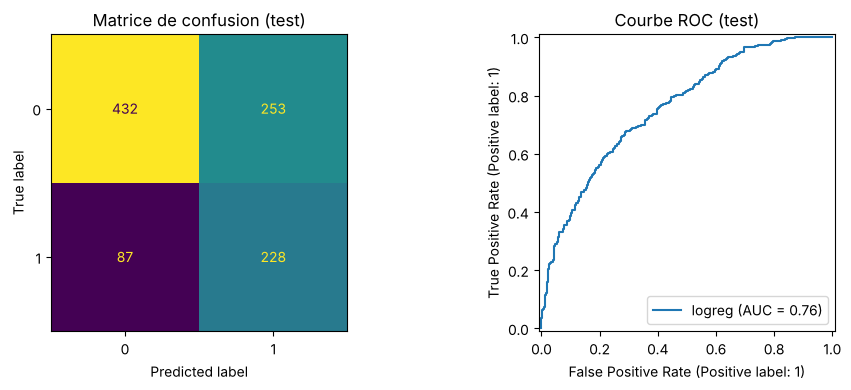

In [13]:
from sklearn.base import clone

X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])
final_model = clone(best_model).fit(X_trainval, y_trainval)

proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= threshold).astype(int)

print(f"ROC-AUC test : {roc_auc_score(y_test, proba_test):.4f}")
print(f"PR-AUC  test : {average_precision_score(y_test, proba_test):.4f}")
print(f"F1      test : {f1_score(y_test, pred_test):.4f}  (seuil {threshold:.2f})\n")
print(classification_report(y_test, pred_test, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1], name=best_name)
axes[0].set_title("Matrice de confusion (test)")
axes[1].set_title("Courbe ROC (test)")
plt.tight_layout()
plt.show()

### Importance des variables (permutation, sur le test)

L'importance par permutation est calculée sur les colonnes **d'origine** puisqu'on passe le pipeline complet.

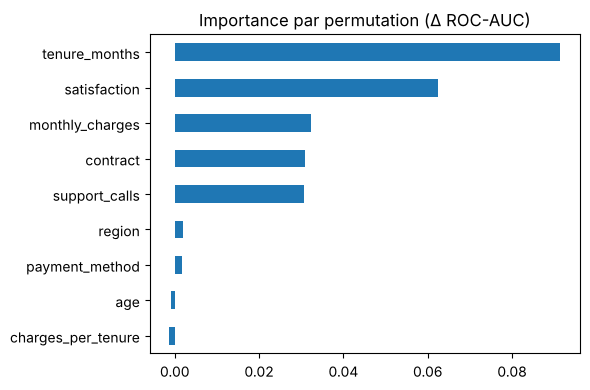

In [14]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
importances = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importances.plot.barh(figsize=(6, 4), title="Importance par permutation (Δ ROC-AUC)")
plt.tight_layout()
plt.show()

## 11. Démonstration : ce qui se passe si on normalise AVANT le split

Avec un simple `StandardScaler`, l'écart est souvent petit sur un gros dataset. La fuite devient **énorme** avec des transformations qui utilisent la cible ou qui sélectionnent des variables. Exemple classique : sélectionner les features les plus corrélées à la cible **avant** la CV sur des données de bruit pur — le score devrait être 0,5 (hasard).

In [15]:
from sklearn.feature_selection import SelectKBest, f_classif


def leakage_demo(n_samples=200, n_features=5000, k=20, seed=42):
    """
    Show the optimistic bias caused by feature selection before splitting.

    Parameters
    ----------
    n_samples : int, default=200
        Number of samples of pure noise.
    n_features : int, default=5000
        Number of random features.
    k : int, default=20
        Number of features kept by ``SelectKBest``.
    seed : int, default=42
        Random seed.

    Returns
    -------
    pandas.Series
        Mean cross-validated ROC-AUC for the leaky and the correct approach.
    """
    rng = np.random.default_rng(seed)
    X_noise = rng.normal(size=(n_samples, n_features))
    y_noise = rng.integers(0, 2, n_samples)
    cv_demo = StratifiedKFold(5, shuffle=True, random_state=seed)

    X_selected = SelectKBest(f_classif, k=k).fit_transform(X_noise, y_noise)
    leaky = cross_validate(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=cv_demo, scoring="roc_auc")

    correct_pipe = Pipeline([("select", SelectKBest(f_classif, k=k)), ("model", LogisticRegression(max_iter=1000))])
    correct = cross_validate(correct_pipe, X_noise, y_noise, cv=cv_demo, scoring="roc_auc")

    return pd.Series(
        {
            "❌ sélection AVANT le split (fuite)": leaky["test_score"].mean(),
            "✅ sélection DANS le pipeline": correct["test_score"].mean(),
        }
    ).round(3)


leakage_demo()

❌ sélection AVANT le split (fuite)    0.914
✅ sélection DANS le pipeline          0.606
dtype: float64

Résultat : la version avec fuite affiche un ROC-AUC très élevé sur des données **purement aléatoires**, alors que la version correcte reste proche du hasard (≈ 0,5–0,6 ; avec seulement 200 lignes la variance est forte). C'est exactement le même mécanisme (en plus discret) quand on scale / encode / impute avant le split.

## 12. Sauvegarde et inférence sur de nouvelles données

In [16]:
def save_model(model, threshold, path):
    """
    Persist a fitted pipeline together with its decision threshold.

    Parameters
    ----------
    model : sklearn.pipeline.Pipeline
        Fitted end-to-end pipeline.
    threshold : float
        Decision threshold chosen on the validation set.
    path : str
        Destination file path.

    Returns
    -------
    None
    """
    joblib.dump({"pipeline": model, "threshold": threshold}, path)


def predict_new(path, X_new):
    """
    Load a saved pipeline and score new raw data.

    Parameters
    ----------
    path : str
        Path of the file written by :func:`save_model`.
    X_new : pandas.DataFrame
        Raw features with the same columns as the training data
        (after :func:`clean_without_fitting`).

    Returns
    -------
    pandas.DataFrame
        Churn probability and predicted label for each row.
    """
    bundle = joblib.load(path)
    proba = bundle["pipeline"].predict_proba(X_new)[:, 1]
    return pd.DataFrame({"proba_churn": proba.round(4), "prediction": (proba >= bundle["threshold"]).astype(int)}, index=X_new.index)


save_model(final_model, threshold, "churn_pipeline.joblib")

new_clients = X_test.head(5).copy()
new_clients.loc[new_clients.index[0], "region"] = "Corse"
predict_new("churn_pipeline.joblib", new_clients)

,proba_churn,prediction
962,0.2485,0
1631,0.0769,0
3822,0.2087,0
881,0.6664,1
49,0.2426,0


Note : on a injecté une région `"Corse"` jamais vue à l'entraînement — grâce à `handle_unknown="ignore"`, le pipeline ne plante pas.

## Récapitulatif

1. Nettoyage **ligne par ligne** → avant le split, OK.
2. **Split** train / val / test (stratifié, temporel ou par groupe selon le cas).
3. Tout ce qui **apprend une statistique** (imputation, scaling, encodage, sélection, PCA, SMOTE) → dans un `Pipeline`, `fit` sur le train uniquement.
4. Comparaison de modèles et tuning en **CV sur le train**.
5. Choix du modèle et du seuil sur la **validation**.
6. Réentraînement sur train + val, **une seule** évaluation sur le **test**.
7. On sauvegarde le **pipeline complet** (préprocessing + modèle), pas juste le modèle.
